In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Data loading and normalization
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

trainset = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=64, shuffle=True)

testset = torchvision.datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)


100.0%


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100.0%


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100.0%


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100.0%

Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



In [2]:
# Define the model with 1 hidden layer
class Model1Hidden(nn.Module):
    def __init__(self):
        super(Model1Hidden, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.softmax(self.fc2(x))
        return x


In [3]:
# Define the model with 2 hidden layers
class Model2Hidden(nn.Module):
    def __init__(self):
        super(Model2Hidden, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


In [4]:
# Training function
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(trainloader)
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# Validation function


def validate(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(testloader)
    val_acc = correct / total
    return val_loss, val_acc


Epoch 1/20 | Train Loss: 1.6943 | Train Acc: 0.7754 | Val Loss: 1.6510 | Val Acc: 0.8137
Epoch 2/20 | Train Loss: 1.6250 | Train Acc: 0.8393 | Val Loss: 1.6351 | Val Acc: 0.8279
Epoch 3/20 | Train Loss: 1.6126 | Train Acc: 0.8502 | Val Loss: 1.6203 | Val Acc: 0.8411
Epoch 4/20 | Train Loss: 1.6038 | Train Acc: 0.8585 | Val Loss: 1.6188 | Val Acc: 0.8438
Epoch 5/20 | Train Loss: 1.5977 | Train Acc: 0.8640 | Val Loss: 1.6101 | Val Acc: 0.8516
Epoch 6/20 | Train Loss: 1.5931 | Train Acc: 0.8692 | Val Loss: 1.6082 | Val Acc: 0.8531
Epoch 7/20 | Train Loss: 1.5880 | Train Acc: 0.8743 | Val Loss: 1.6023 | Val Acc: 0.8590
Epoch 8/20 | Train Loss: 1.5844 | Train Acc: 0.8780 | Val Loss: 1.6017 | Val Acc: 0.8590
Epoch 9/20 | Train Loss: 1.5813 | Train Acc: 0.8804 | Val Loss: 1.6001 | Val Acc: 0.8598
Epoch 10/20 | Train Loss: 1.5784 | Train Acc: 0.8832 | Val Loss: 1.5943 | Val Acc: 0.8667
Epoch 11/20 | Train Loss: 1.5755 | Train Acc: 0.8861 | Val Loss: 1.5935 | Val Acc: 0.8672
Epoch 12/20 | Train

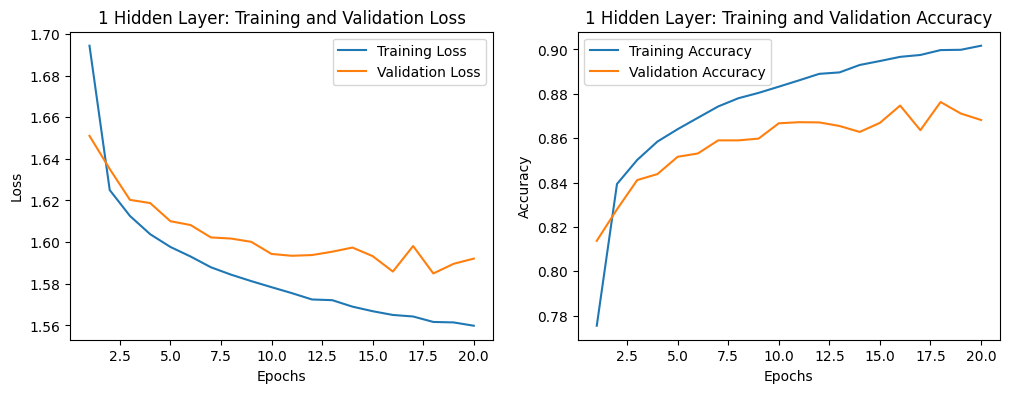

Epoch 1/20 | Train Loss: 1.6863 | Train Acc: 0.7825 | Val Loss: 1.6423 | Val Acc: 0.8213
Epoch 2/20 | Train Loss: 1.6278 | Train Acc: 0.8345 | Val Loss: 1.6284 | Val Acc: 0.8341
Epoch 3/20 | Train Loss: 1.6152 | Train Acc: 0.8466 | Val Loss: 1.6207 | Val Acc: 0.8410
Epoch 4/20 | Train Loss: 1.6103 | Train Acc: 0.8507 | Val Loss: 1.6146 | Val Acc: 0.8470
Epoch 5/20 | Train Loss: 1.6057 | Train Acc: 0.8555 | Val Loss: 1.6145 | Val Acc: 0.8453
Epoch 6/20 | Train Loss: 1.5995 | Train Acc: 0.8619 | Val Loss: 1.6136 | Val Acc: 0.8465
Epoch 7/20 | Train Loss: 1.5968 | Train Acc: 0.8642 | Val Loss: 1.6087 | Val Acc: 0.8523
Epoch 8/20 | Train Loss: 1.5921 | Train Acc: 0.8689 | Val Loss: 1.6026 | Val Acc: 0.8571
Epoch 9/20 | Train Loss: 1.5887 | Train Acc: 0.8721 | Val Loss: 1.6024 | Val Acc: 0.8582
Epoch 10/20 | Train Loss: 1.5890 | Train Acc: 0.8718 | Val Loss: 1.6064 | Val Acc: 0.8531
Epoch 11/20 | Train Loss: 1.5842 | Train Acc: 0.8767 | Val Loss: 1.6045 | Val Acc: 0.8557
Epoch 12/20 | Train

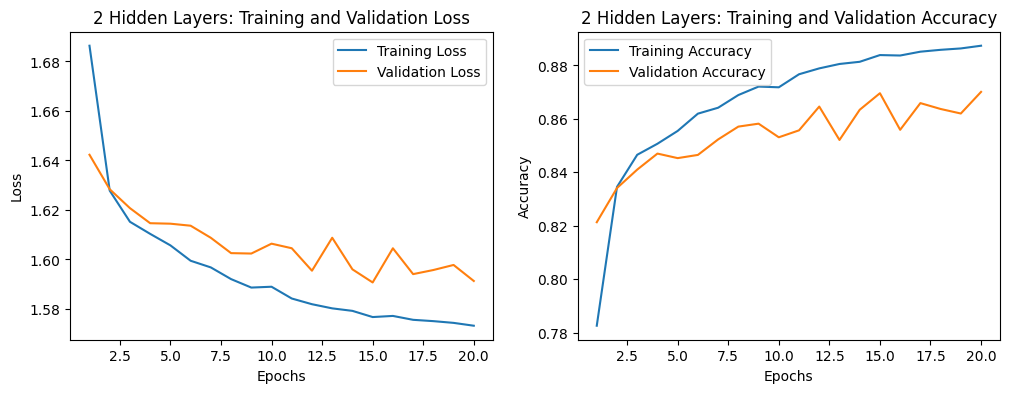

In [5]:
# Plotting function
def plot_history(train_hist, val_hist, model_name):
    epochs = range(1, len(train_hist['loss']) + 1)

    plt.figure(figsize=(12, 4))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_hist['loss'], label='Training Loss')
    plt.plot(epochs, val_hist['loss'], label='Validation Loss')
    plt.title(f'{model_name}: Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_hist['accuracy'], label='Training Accuracy')
    plt.plot(epochs, val_hist['accuracy'], label='Validation Accuracy')
    plt.title(f'{model_name}: Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

# Main loop for training and validation


def run_training(model, trainloader, testloader, device, epochs=20):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_history = {'loss': [], 'accuracy': []}
    val_history = {'loss': [], 'accuracy': []}

    for epoch in range(epochs):
        train_loss, train_acc = train(
            model, trainloader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, testloader, criterion, device)

        train_history['loss'].append(train_loss)
        train_history['accuracy'].append(train_acc)
        val_history['loss'].append(val_loss)
        val_history['accuracy'].append(val_acc)

        print(f'Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Train Acc: {
              train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}')

    return train_history, val_history


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Model with 1 hidden layer
model_1_hidden = Model1Hidden().to(device)
train_hist_1, val_hist_1 = run_training(
    model_1_hidden, trainloader, testloader, device)
plot_history(train_hist_1, val_hist_1, '1 Hidden Layer')

# Model with 2 hidden layers
model_2_hidden = Model2Hidden().to(device)
train_hist_2, val_hist_2 = run_training(
    model_2_hidden, trainloader, testloader, device)
plot_history(train_hist_2, val_hist_2, '2 Hidden Layers')
